# 12 · Which known nearby giant planets could Lazuli's coronagraph image in reflected light within a day?

Radial-velocity surveys have found dozens of cold giants around bright stars within 20 pc, but almost none have been seen directly: in reflected light they sit at contrasts of $10^{-8}$–$10^{-10}$ and separations of a few tenths of an arcsec. Here we pull the real RV giants from the NASA Exoplanet Archive, turn their orbits into a reflected-light contrast and a maximum separation, and ask the ESC exposure-time calculator how long each one takes to reach S/N = 5.

**Instrument / code:** Lazuli ESC (ExtraSolar Coronagraph), `esc_etc.Simulation.from_default(...)` → `sim.update(...)` → `sim.get_int_time_for_snr(...)`; NASA Exoplanet Archive TAP (`pscomppars`).

## Prompt to try in Jupyter AI

> Query the NASA Exoplanet Archive TAP service (table `pscomppars`) for radial-velocity planets with 0.3 < M sin i (or true mass) < 15 M_Jup, a > 1 AU, distance < 20 pc and host V < 7; cache the result as a CSV so the notebook re-runs offline.
> For each planet compute the maximum angular separation a/d (arcsec) and the reflected-light contrast at quadrature, C = A_g · (1/π) · (R_p/a)², with geometric albedo A_g = 0.5, a Lambert phase function, circular orbits, and the archive radius (1 R_Jup if missing).
> Then use `esc_etc.Simulation.from_default(filter="R3", contrast=1e-8, ppgain=10)` and, per planet, `sim.update(scene__star__mag=V, scene__star__band="johnson_v", scene__planet__deltamag=-2.5*log10(C), coronagraph__separation=sep)` and `sim.get_int_time_for_snr(5, frame_time)` to get the time to S/N = 5 (frame time 1000 s, capped below `sim.saturation_time()`).
> Flag planets outside the coronagraph working angle using the FPM off-axis throughput table (`sim.coronagraph._lamD`, `_throughput`).
> Make a log-log plot of contrast vs separation, points colored by time to S/N = 5, with the working-angle limits, the post-processing floor and a 1-day sensitivity curve, and label the planet names.
> Print a sorted table, state every assumption, and check the units of separation (arcsec vs λ/D).

## Setup

In [1]:
import io, urllib.parse, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import astropy.units as u
from scipy.optimize import brentq
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
# plt.style.use('gks')

import esc_etc
from esc_etc import Simulation
warnings.filterwarnings('ignore', module='synphot')

CACHE = Path('data/12_nearby_rv_giants.csv')
THUMB = Path('thumbs/12_reflected_light_giants.png')
print('esc_etc', esc_etc.__version__)

esc_etc 0.1.0


## 1. The sample: RV giants around bright, nearby stars

A criteria-based query rather than a hand-picked list: every RV planet in `pscomppars` with $0.3 < M\,(\sin i) < 15\,M_J$ (the upper cut keeps π Men b at 14 $M_J$), $a > 1$ AU, $d < 20$ pc and host $V < 7$. The result is cached so the notebook runs offline.

In [2]:
QUERY = '''select pl_name, hostname, pl_orbsmax, pl_orbeccen, pl_bmassj, pl_bmassprov, pl_radj,
                  sy_dist, sy_vmag, st_spectype
           from pscomppars
           where discoverymethod = 'Radial Velocity' and sy_dist < 20 and sy_vmag < 7
             and pl_bmassj > 0.3 and pl_bmassj < 15 and pl_orbsmax > 1'''

if CACHE.exists():
    df = pd.read_csv(CACHE)
    print(f'loaded {len(df)} planets from cache {CACHE}')
else:
    url = ('https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query='
           + urllib.parse.quote(QUERY) + '&format=csv')
    df = pd.read_csv(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
    CACHE.parent.mkdir(exist_ok=True)
    df.to_csv(CACHE, index=False)
    print(f'queried {len(df)} planets, cached to {CACHE}')
df[['pl_name', 'pl_orbsmax', 'pl_bmassj', 'pl_radj', 'sy_dist', 'sy_vmag', 'st_spectype']].sort_values('sy_dist').head(8)

queried 25 planets, cached to ../data/12_nearby_rv_giants.csv


,pl_name,pl_orbsmax,pl_bmassj,pl_radj,sy_dist,sy_vmag,st_spectype
15,eps Eri b,3.53000,1.000,1.23,3.20260,3.71548,K2 V
10,eps Ind A b,15.76000,6.500,1.13,3.63857,4.69000,K5 V
19,HD 219134 h,3.11000,0.340,1.14,6.53127,5.56911,K3 V
2,HD 62509 b,1.64000,2.300,1.19,10.34000,1.12512,K0IIIvar
14,HD 115404 A c,11.36400,10.319,1.11,10.98160,6.50066,K2V
0,55 Cnc d,5.60000,3.878,1.16,12.58550,5.95084,G8 V
8,HD 147513 b,1.32000,1.210,1.22,12.90320,5.37000,G3/5V
22,ups And d,2.51329,10.250,1.11,13.40540,4.09565,F8 V


## 2. Separation and reflected-light contrast

For a circular orbit seen at quadrature (phase angle 90°) the projected separation is maximal, $\theta = a/d$, and a Lambert sphere gives

$$C = A_g\,\Phi(90^\circ)\left(\frac{R_p}{a}\right)^2, \qquad \Phi_\mathrm{Lambert}(90^\circ) = 1/\pi .$$

Assumptions: $A_g = 0.5$ (Jupiter-like at red wavelengths), circular orbit at the archive semi-major axis, and the archive radius. For these non-transiting planets `pl_radj` is itself a mass–radius estimate (≈1.1–1.3 $R_J$); we fall back to 1 $R_J$ where it is missing.

In [3]:
A_G, PHI_90 = 0.5, 1 / np.pi
R_p = df.pl_radj.fillna(1.0).values * u.R_jup
a = df.pl_orbsmax.values * u.AU
df['radius_rj'] = R_p.to_value(u.R_jup)
df['sep_arcsec'] = df.pl_orbsmax / df.sy_dist          # AU / pc = arcsec
df['contrast'] = (A_G * PHI_90 * (R_p / a) ** 2).decompose().value
df['deltamag'] = -2.5 * np.log10(df.contrast)
print(f"radius filled with 1 R_J for {df.pl_radj.isna().sum()} planets")
print(f"contrast range {df.contrast.min():.1e} - {df.contrast.max():.1e}, separation range {df.sep_arcsec.min():.2f} - {df.sep_arcsec.max():.2f} arcsec")

radius filled with 1 R_J for 2 planets
contrast range 1.1e-10 - 3.3e-08, separation range 0.07 - 4.33 arcsec


## 3. The ESC model and its working angle

Baseline: the widest red ESC filter (R3 = F659W, end-of-life curve), raw dark-hole contrast $10^{-8}$ (the L2 spec value in the vendored config), post-processing gain 10, no reference-star subtraction. The FPM (charge-6 vortex) off-axis throughput table sets the usable range: we call the separation where throughput reaches half its maximum the inner working angle (IWA), and the table edge is the outer limit of what the ETC can model (it raises an error beyond it).

In [4]:
RAW_C, PPGAIN, FILTER, FRAME = 1e-8, 10, 'R3', 1000 * u.s
sim = Simulation.from_default(filter=FILTER, contrast=RAW_C, ppgain=PPGAIN, hoststar_band='johnson_v')

cg = sim.coronagraph
lamD_as = (cg.primary_filter / cg.diameter_primary).to_value(u.arcsec, equivalencies=u.dimensionless_angles())
sep_tab, thr_tab = cg._lamD * lamD_as, cg._throughput
IWA = sep_tab[np.argmax(thr_tab >= 0.5 * thr_tab.max())]
OWA = sep_tab.max() * 0.999          # stay just inside the table edge
print(f"lambda/D = {lamD_as*1e3:.1f} mas at {cg.primary_filter.to(u.nm):.0f}, D = {cg.diameter_primary}")
print(f"peak FPM throughput {thr_tab.max():.2f};  IWA (50% of peak) = {IWA:.3f}\"  ;  table edge = {sep_tab.max():.3f}\" ({cg._lamD.max():.0f} lambda/D)")
print(f"S/N=5 is unreachable below C = 5 x raw/ppgain = {5*RAW_C/PPGAIN:.1e} (post-processing floor)")

lambda/D = 45.3 mas at 659 nm, D = 3.0 m
peak FPM throughput 0.65;  IWA (50% of peak) = 0.165"  ;  table edge = 0.906" (20 lambda/D)
S/N=5 is unreachable below C = 5 x raw/ppgain = 5.0e-09 (post-processing floor)


## 4. Time to S/N = 5 for every planet

Host magnitudes are catalog $V$ (`hoststar_band='johnson_v'`), the planet is `deltamag` fainter in the ESC band (grey albedo, so the contrast is the same in every band). Frames are 1000 s (read noise matters at 100 s for these faint rates), capped at half the saturation time for the brightest hosts. `int_time_continuous` is `nan` when S/N = 5 lies above the post-processing floor.

In [5]:
def time_to_snr5(V, deltamag, sep, ppgain=PPGAIN):
    sim.update(scene__star__mag=V, scene__planet__deltamag=deltamag,
               coronagraph__separation=sep, coronagraph__ppgain=ppgain)
    frame = min(FRAME, 0.5 * sim.saturation_time())
    t = sim.get_int_time_for_snr(5, frame)['int_time_continuous'][0].to_value(u.hr)
    sim.reset()   # back to the from_default state (V-band host, ppgain=10)
    return t

df['in_wa'] = (df.sep_arcsec >= IWA) & (df.sep_arcsec <= OWA)
df['inside_table'] = df.sep_arcsec <= OWA
for g, col in [(PPGAIN, 't_hr'), (30, 't_hr_pp30')]:
    df[col] = [time_to_snr5(r.sy_vmag, r.deltamag, r.sep_arcsec, g) if r.inside_table else np.nan
               for r in df.itertuples()]

show = df.sort_values('t_hr')[['pl_name', 'sy_vmag', 'sep_arcsec', 'contrast', 'in_wa', 't_hr', 't_hr_pp30']]
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.width', 120):
    print(show.to_string(index=False))

      pl_name  sy_vmag  sep_arcsec  contrast  in_wa    t_hr  t_hr_pp30
   HD 62509 b     1.13       0.159  1.91e-08  False 0.00424    0.00398
    gam Cep b     3.23        0.14  1.17e-08  False   0.103     0.0857
      7 CMa b     3.95      0.0887  1.69e-08  False   0.343      0.316
      7 CMa c     3.95       0.109  1.21e-08  False   0.384      0.324
  HD 147513 b     5.37       0.102   3.1e-08  False   0.662      0.647
   HD 27442 b     4.44      0.0696  3.29e-08  False   0.672      0.658
    ups And d      4.1       0.187  7.09e-09   True   0.748      0.398
     47 UMa b     5.03       0.152  1.15e-08  False   0.928      0.768
    bet Pic c     3.85       0.137  6.25e-09  False    1.45      0.565
  HD 160691 b     5.12      0.0962  1.62e-08  False    1.56       1.43
   HD 10647 b     5.52       0.116  1.35e-08  False    2.55       2.24
     14 Her b     6.62       0.158  5.66e-09  False     179         43
   HD 39091 b     5.65        0.18  4.09e-09   True     NaN       12.8
  HD 2

In [6]:
ok = df.in_wa & (df.t_hr <= 24)
print(f"{len(df)} RV giants in the sample; {df.inside_table.sum()} inside the FPM table, {df.in_wa.sum()} between IWA and table edge")
print(f"S/N=5 in <= 1 day (ppgain={PPGAIN}), inside the working angle: {ok.sum()} ->", ', '.join(df[ok].sort_values('t_hr').pl_name))
inner = df.inside_table & ~df.in_wa & (df.t_hr <= 24)
print(f"<= 1 day but inside the IWA (throughput < 50% of peak): {inner.sum()} ->", ', '.join(df[inner].pl_name))
print(f"unreachable at S/N=5 with ppgain={PPGAIN} (below floor): {(df.inside_table & df.t_hr.isna()).sum()};  with ppgain=30: {(df.inside_table & df.t_hr_pp30.isna()).sum()}")
print(f"beyond the FPM table edge ({sep_tab.max():.2f}\"): ", ', '.join(df[~df.inside_table].pl_name))

25 RV giants in the sample; 21 inside the FPM table, 10 between IWA and table edge
S/N=5 in <= 1 day (ppgain=10), inside the working angle: 1 -> ups And d
<= 1 day but inside the IWA (throughput < 50% of peak): 10 -> HD 27442 b, HD 160691 b, bet Pic c, 47 UMa b, HD 147513 b, HD 62509 b, gam Cep b, 7 CMa b, 7 CMa c, HD 10647 b
unreachable at S/N=5 with ppgain=10 (below floor): 9;  with ppgain=30: 3
beyond the FPM table edge (0.91"):  eps Ind A b, eps Eri b, HD 115404 A c, HD 145675 c


## 5. A 1-day sensitivity curve

For context, solve for the contrast that reaches S/N = 5 in exactly 24 h versus separation, for a $V = 6$ host (brentq on `deltamag`). Brighter hosts sit even closer to the floor.

In [7]:
seps = np.geomspace(IWA * 0.6, OWA, 15)
def c_1day(V, sep):
    f = lambda dm: np.nan_to_num(time_to_snr5(V, dm, sep), nan=1e9) - 24.0
    return 10 ** (-0.4 * brentq(f, 10, 21.5, xtol=1e-3))
curves = {V: np.array([c_1day(V, s) for s in seps]) for V in (6,)}
for V, c in curves.items():
    print(f"V={V}: 1-day 5-sigma contrast {c.min():.1e} (best) ... {c.max():.1e} (at {seps[0]:.2f}\")")

V=6: 1-day 5-sigma contrast 5.5e-09 (best) ... 9.4e-09 (at 0.10")


## Hero figure

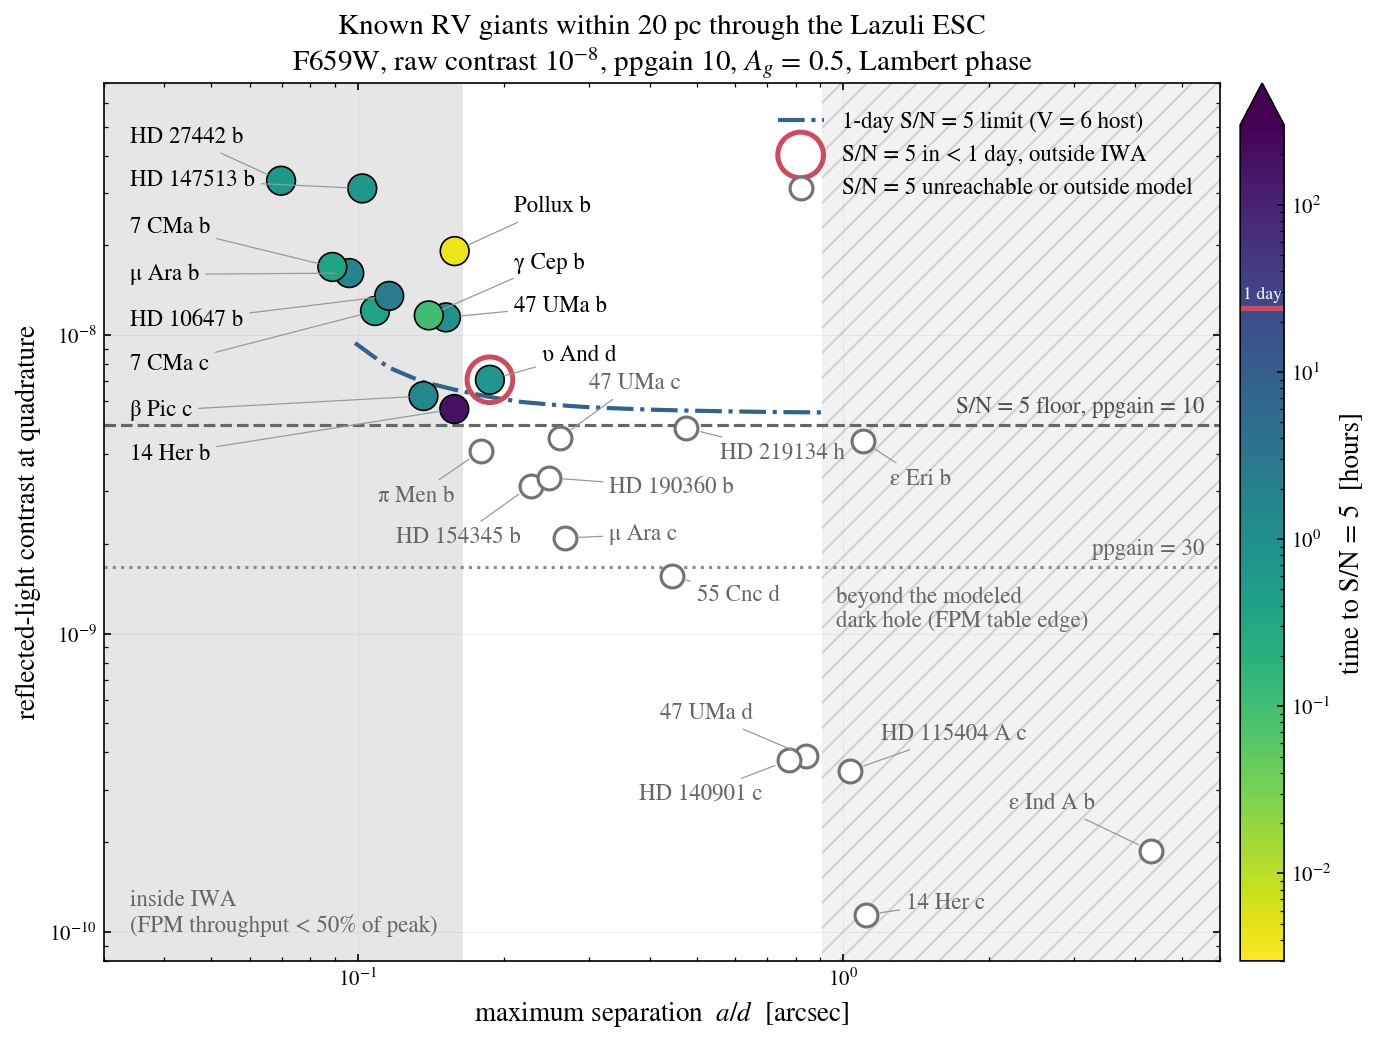

In [8]:
NAME = {'HD 62509 b': 'Pollux b', 'HD 39091 b': 'π Men b', 'HD 160691 b': 'μ Ara b', 'HD 160691 c': 'μ Ara c',
        'HD 145675 c': '14 Her c', 'gam Cep b': 'γ Cep b', 'eps Eri b': 'ε Eri b', 'eps Ind A b': 'ε Ind A b',
        'ups And d': 'υ And d', 'bet Pic c': 'β Pic c'}
TXT = {   # label position in data coordinates (separation, contrast)
    'HD 27442 b': (0.034, 4.6e-8), 'HD 147513 b': (0.034, 3.3e-8), '7 CMa b': (0.034, 2.3e-8),
    'HD 160691 b': (0.034, 1.6e-8), 'HD 10647 b': (0.034, 1.12e-8), '7 CMa c': (0.034, 8.0e-9),
    'bet Pic c': (0.034, 5.6e-9), '14 Her b': (0.034, 4.0e-9),
    'HD 62509 b': (0.21, 2.7e-8), 'gam Cep b': (0.21, 1.75e-8), '47 UMa b': (0.21, 1.25e-8),
    'ups And d': (0.24, 8.6e-9), 'HD 39091 b': (0.11, 2.9e-9),
    'HD 219134 h': (0.56, 4.05e-9), '47 UMa c': (0.30, 6.9e-9), 'HD 190360 b': (0.33, 3.1e-9),
    'HD 154345 b': (0.12, 2.1e-9), 'HD 160691 c': (0.33, 2.15e-9), '55 Cnc d': (0.5, 1.35e-9),
    'eps Eri b': (1.25, 3.3e-9), '47 UMa d': (0.42, 5.4e-10), 'HD 140901 c': (0.38, 2.9e-10),
    'HD 115404 A c': (1.2, 4.6e-10), 'HD 145675 c': (1.35, 1.25e-10), 'eps Ind A b': (2.2, 2.7e-10),
}
XMIN, XMAX, YMIN, YMAX = 0.03, 6, 8e-11, 7e-8

fig, ax = plt.subplots(figsize=(11.5, 7.6))
ax.axvspan(XMIN, IWA, color='0.9', lw=0, zorder=0)
ax.axvspan(OWA, XMAX, facecolor='0.95', hatch='//', edgecolor='0.82', lw=0, zorder=0)
ax.text(0.034, 1.0e-10, 'inside IWA\n(FPM throughput < 50% of peak)', fontsize=11, color='0.4')
ax.text(OWA * 1.07, 1.05e-9, 'beyond the modeled\ndark hole (FPM table edge)', fontsize=11, color='0.4')

floor10, floor30 = 5 * RAW_C / PPGAIN, 5 * RAW_C / 30
ax.axhline(floor10, color='0.4', ls='--', lw=1.5)
ax.text(XMAX * 0.93, floor10 * 1.1, f'S/N = 5 floor, ppgain = {PPGAIN}', ha='right', fontsize=11, color='0.3')
ax.axhline(floor30, color='0.55', ls=':', lw=1.5)
ax.text(XMAX * 0.93, floor30 * 1.1, 'ppgain = 30', ha='right', fontsize=11, color='0.4')
ax.plot(seps, curves[6], color='#30638e', ls='-.', lw=2, label='1-day S/N = 5 limit (V = 6 host)')

good = df.inside_table & df.t_hr.notna()
norm = LogNorm(0.003, 300)
sc = ax.scatter(df.sep_arcsec[good], df.contrast[good], c=df.t_hr[good], cmap='viridis_r', norm=norm,
                s=190, edgecolor='k', lw=0.8, zorder=5)
day = good & df.in_wa & (df.t_hr <= 24)
ax.scatter(df.sep_arcsec[day], df.contrast[day], s=480, facecolor='none', edgecolor='#d1495b', lw=2.4, zorder=6,
           label='S/N = 5 in < 1 day, outside IWA')
ax.scatter(df.sep_arcsec[~good], df.contrast[~good], s=120, facecolor='white', edgecolor='0.45', lw=1.5, zorder=4,
           label='S/N = 5 unreachable or outside model')
for r in df.itertuples():
    xy_txt = TXT.get(r.pl_name, (r.sep_arcsec * 1.12, r.contrast * 1.1))
    ax.annotate(NAME.get(r.pl_name, r.pl_name), (r.sep_arcsec, r.contrast), xytext=xy_txt, fontsize=11,
                va='center', color='k' if good[r.Index] else '0.4', zorder=7,
                arrowprops=dict(arrowstyle='-', color='0.6', lw=0.6, shrinkA=1, shrinkB=7))

cb = fig.colorbar(sc, ax=ax, pad=0.015, extend='max')
cb.set_label('time to S/N = 5  [hours]')
cb.ax.axhline(24, color='#d1495b', lw=2.5)
cb.ax.text(0.5, 26, '1 day', color='white', fontsize=8.5, ha='center', va='bottom', transform=cb.ax.get_yaxis_transform())
ax.set(xscale='log', yscale='log', xlim=(XMIN, XMAX), ylim=(YMIN, YMAX),
       xlabel='maximum separation  $a/d$  [arcsec]', ylabel='reflected-light contrast at quadrature')
ax.set_title(f'Known RV giants within 20 pc through the Lazuli ESC\n'
             f'F659W, raw contrast $10^{{-8}}$, ppgain {PPGAIN}, $A_g$ = 0.5, Lambert phase', fontsize=14)
ax.legend(loc='upper right', fontsize=11, borderaxespad=0.8)
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

Of the 25 RV giants within 20 pc around $V<7$ hosts, the ETC puts 11 at S/N = 5 in under a day, but only **υ And d** (0.19″, $Cpprox7	imes10^{-9}$, 0.75 h) does so outside the 0.165″ half-throughput IWA; the other ten (Pollux b at 15 s, γ Cep b, 47 UMa b, β Pic c, ...) sit at 0.07–0.16″, where the constant-raw-contrast assumption is optimistic. Most cold giants in the working angle (9 of 10) are fainter than the $5	imes10^{-9}$ floor set by raw contrast $10^{-8}$ and ppgain = 10; at ppgain = 30, 47 UMa c (2.6 h), HD 219134 h (3.6 h), π Men b (12.8 h) and HD 190360 b (17 h) also come in under a day. The nearest wide giants (ε Eri b, ε Ind A b, 14 Her c) lie beyond the 0.91″ edge of the modeled dark hole.

## Caveats & next steps

- **Model limits (from the esc-etc docs):** a purely analytic photometric model. Raw contrast is a single number independent of separation, the FPM throughput is applied as a flat scalar to every rate (including zodi/exozodi), the planet and host have flat spectral shapes, `ppgain` is an *assumed* speckle-suppression factor (not a prediction), and no PSF/image simulation, roll/ADI self-subtraction or pointing jitter is included. The FPM table stops at 20 λ/D; the real dark-hole OWA is set by the DM and is not in this config.
- **Planet model:** circular orbits at quadrature, grey $A_g = 0.5$, Lambert phase, mass–radius radii. Eccentric orbits (14 Her b, HD 190360 b, pi Men b) and inclinations from Gaia–Hipparcos astrometry change both the separation and the phase on a given date; true masses (not $M\sin i$) matter for the radius only weakly.
- **Extend it:** (1) use astrometric orbits and ephemerides to compute separation and phase angle on real dates in 2028–2032 and build an observing calendar; (2) swap in RDI (`coronagraph__subtraction='rdi'`) with realistic reference stars and the charged time; (3) put the eps Eri b / eps Ind A b / 14 Her c class of wide planets into reach by asking what dark-hole OWA they would need, or compare narrow vs wide filters (R1 vs R3) for a color measurement.